In [1]:
# ==============================================================================
# Model 2 (Advanced): Random Forest Classifier untuk Klasifikasi Kerusakan Jalan
# ==============================================================================

import os
import time
import joblib
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [2]:
npz_path = "classical_features.npz"  # Sesuaikan path jika berada di subfolder (misal: "Data/processed/classical_features.npz")
data = np.load(npz_path, allow_pickle=True)

print("Key/array yang tersedia di dalam classical_features.npz:", data.files)

# Mengambil array train & validation (sesuaikan nama key jika berbeda, misal X_valid)
X_train = data["X_train"]
y_train = data["y_train"]
X_val   = data["X_val"] if "X_val" in data.files else data["X_valid"]
y_val   = data["y_val"] if "y_val" in data.files else data["y_valid"]

print(f"Dimensi X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Dimensi X_val  : {X_val.shape}, y_val  : {y_val.shape}")

# Standarisasi fitur (fit hanya pada X_train untuk mencegah data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)

Key/array yang tersedia di dalam classical_features.npz: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test']
Dimensi X_train: (465, 6180), y_train: (465,)
Dimensi X_val  : (133, 6180), y_val  : (133,)



=== HASIL EVALUASI MODEL 2: RANDOM FOREST (VALIDATION SET) ===
Training Time   : 3.9383 detik
Accuracy        : 0.5789
Macro Precision : 0.3452
Macro Recall    : 0.3582
Macro F1-Score  : 0.3281

              precision    recall  f1-score   support

     Low (0)     0.0000    0.0000    0.0000         9
  Medium (1)     0.4286    0.1915    0.2647        47
Critical (2)     0.6071    0.8831    0.7196        77

    accuracy                         0.5789       133
   macro avg     0.3452    0.3582    0.3281       133
weighted avg     0.5030    0.5789    0.5101       133



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


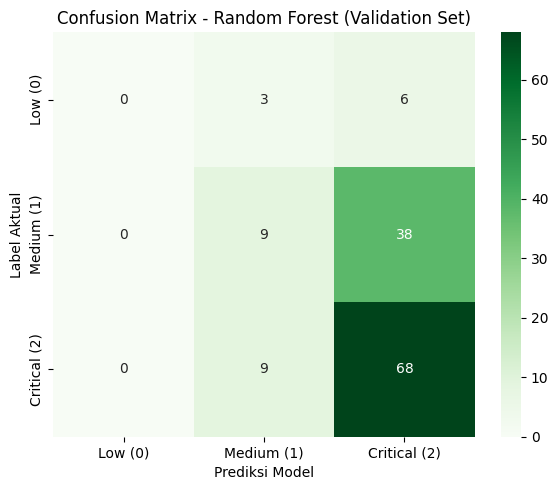

In [3]:
# ------------------------------------------------------------------------------
# 2. TRAINING MODEL 2 (ADVANCED): RANDOM FOREST CLASSIFIER
# ------------------------------------------------------------------------------
rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    max_depth=None,
    min_samples_split=2,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

start_time = time.time()
rf_model.fit(X_train_scaled, y_train)
rf_train_time = time.time() - start_time

# Prediksi pada Validation Set
y_val_pred_rf = rf_model.predict(X_val_scaled)

# Hitung Metrik Evaluasi
CLASSES = ["Low (0)", "Medium (1)", "Critical (2)"]
rf_acc  = accuracy_score(y_val, y_val_pred_rf)
rf_prec = precision_score(y_val, y_val_pred_rf, average='macro', zero_division=0)
rf_rec  = recall_score(y_val, y_val_pred_rf, average='macro', zero_division=0)
rf_f1   = f1_score(y_val, y_val_pred_rf, average='macro', zero_division=0)

print("\n=== HASIL EVALUASI MODEL 2: RANDOM FOREST (VALIDATION SET) ===")
print(f"Training Time   : {rf_train_time:.4f} detik")
print(f"Accuracy        : {rf_acc:.4f}")
print(f"Macro Precision : {rf_prec:.4f}")
print(f"Macro Recall    : {rf_rec:.4f}")
print(f"Macro F1-Score  : {rf_f1:.4f}\n")
print(classification_report(y_val, y_val_pred_rf, target_names=CLASSES, digits=4))

# Plot Confusion Matrix Random Forest
cm_rf = confusion_matrix(y_val, y_val_pred_rf)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', xticklabels=CLASSES, yticklabels=CLASSES)
plt.title("Confusion Matrix - Random Forest (Validation Set)")
plt.xlabel("Prediksi Model")
plt.ylabel("Label Aktual")
plt.tight_layout()
plt.show()


=== TABEL PERBANDINGAN AWAL PADA VALIDATION SET ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Training Time (s)
0,Model 1: Logistic Regression (Baseline),0.548872,0.355844,0.379571,0.366777,2.7463
1,Model 2: Random Forest (Advanced),0.578947,0.345238,0.358202,0.328094,3.9383


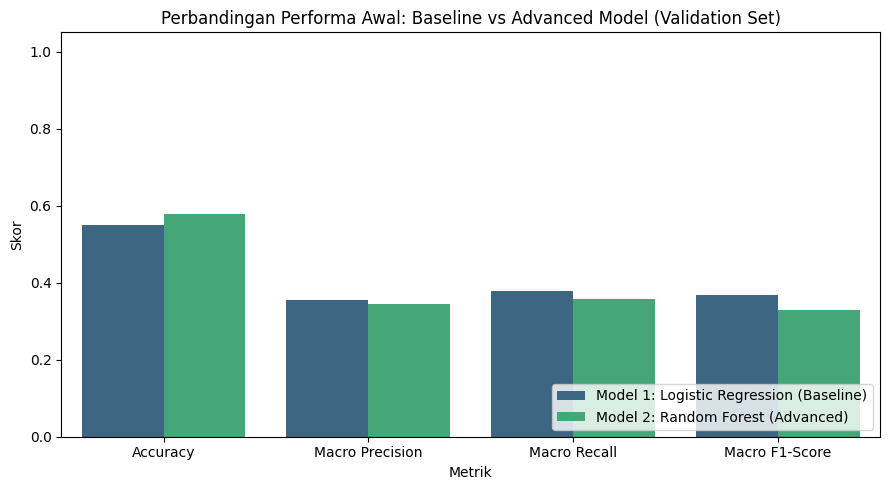

In [4]:
# ------------------------------------------------------------------------------
# 3. PERBANDINGAN AWAL: BASELINE (LOGISTIC REGRESSION) VS ADVANCED (RANDOM FOREST)
# ------------------------------------------------------------------------------
# Latih ulang Baseline dengan data yang sama untuk perbandingan langsung
start_base = time.time()
baseline_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
baseline_model.fit(X_train_scaled, y_train)
base_train_time = time.time() - start_base
y_val_pred_base = baseline_model.predict(X_val_scaled)

comparison_df = pd.DataFrame({
    "Model": ["Model 1: Logistic Regression (Baseline)", "Model 2: Random Forest (Advanced)"],
    "Accuracy": [
        accuracy_score(y_val, y_val_pred_base),
        rf_acc
    ],
    "Macro Precision": [
        precision_score(y_val, y_val_pred_base, average='macro', zero_division=0),
        rf_prec
    ],
    "Macro Recall": [
        recall_score(y_val, y_val_pred_base, average='macro', zero_division=0),
        rf_rec
    ],
    "Macro F1-Score": [
        f1_score(y_val, y_val_pred_base, average='macro', zero_division=0),
        rf_f1
    ],
    "Training Time (s)": [
        round(base_train_time, 4),
        round(rf_train_time, 4)
    ]
})

print("\n=== TABEL PERBANDINGAN AWAL PADA VALIDATION SET ===")
display(comparison_df)

# Visualisasi Perbandingan Metrik
comparison_melted = comparison_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-Score"],
    var_name="Metrik",
    value_name="Skor"
)

plt.figure(figsize=(9, 5))
sns.barplot(data=comparison_melted, x="Metrik", y="Skor", hue="Model", palette="viridis")
plt.ylim(0, 1.05)
plt.title("Perbandingan Performa Awal: Baseline vs Advanced Model (Validation Set)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [5]:
# ------------------------------------------------------------------------------
# 4. SIMPAN MODEL UNTUK REPRODUKTIFITAS
# ------------------------------------------------------------------------------
os.makedirs("Models", exist_ok=True)
joblib.dump(rf_model, "Models/rf_advanced_initial.pkl")
joblib.dump(scaler, "Models/feature_scaler.pkl")
print("Model berhasil disimpan ke Models/rf_advanced_initial.pkl")

Model berhasil disimpan ke Models/rf_advanced_initial.pkl
